**Import needed libraries**

In [1]:
import pandas as pd
import seaborn as sns
import plotly_express as px

import matplotlib.pyplot as plt

import warnings

warnings.filterwarnings('ignore')  # gör så att ni slipper se icke kritiska felmeddelanden

## 1 - Getting started

This project will be centered around the Chicago Crime & selected Census data. Start of by downloading both datasets.

**1.1** Read through the documentation for both datasets. Do this *thoroughly*!

Chicago crime data : https://data.cityofchicago.org/Public-Safety/Crimes-2001-to-Present/ijzp-q8t2

Chicago census data : https://data.cityofchicago.org/Health-Human-Services/Census-Data-Selected-socioeconomic-indicators-in-C/kn9c-c2s2



**1.2** Now download both datasets as .csv files. You get the option to download by frist clicking on the 'Export' tab. Make sure you select the data in CSV format.

Be mindful that the crime dataset is over 2GB in size, so it might take awhile to download.

Once downloaded, rename the files chicago_crime.csv & chicago_census.csv, respectively, and put them in the same folder as this notebook.

**1.3** Load data. The following reads should now work.

In [2]:
chicago_crime_2001_to_2025_df = pd.read_csv('chicago_crime.csv')
chicago_census_2008_to_2012_df = pd.read_csv('chicago_census.csv')

**1.4** The census data only contains records that apply for the period 2008-2012, while the crime dataset runs from 2001-2024. 

Therefore, begin by filtering the crime data so that you get a dataframe that contains records only for the period 2008-2012. 

*Hint*: You'll be filtering based on date quite alot in this project, and it's therefore very advisable to transform the existing *Date* column into datetime-format. 

To simplify further, you could perhaps also create new columns that indicate *Year*, *Month*, *Day* and *Hour*. 

You might also find that other types of indicator columns could be useful. Feel free to come back and add them here later.

**Important:** For the remainder of this project, we will only work with data for the year 2008-2012.

In [3]:
# Convert to datetime format

chicago_crime_2001_to_2025_df['Date'] = pd.to_datetime(chicago_crime_2001_to_2025_df['Date'])

In [4]:
# Adding Year, Month ,Day ,Hour, Weekday and Minute columns in 'Chicago_crime.csv'

chicago_crime_2001_to_2025_df['Year']    = chicago_crime_2001_to_2025_df['Date'].dt.year
chicago_crime_2001_to_2025_df['Month']  = chicago_crime_2001_to_2025_df['Date'].dt.month
chicago_crime_2001_to_2025_df['Day']     = chicago_crime_2001_to_2025_df['Date'].dt.day
chicago_crime_2001_to_2025_df['Weekday'] = chicago_crime_2001_to_2025_df['Date'].dt.day_name()

chicago_crime_2001_to_2025_df['Hour']    = chicago_crime_2001_to_2025_df['Date'].dt.hour
chicago_crime_2001_to_2025_df['Minute']  = chicago_crime_2001_to_2025_df['Date'].dt.minute

chicago_crime_2001_to_2025_df.head()

,ID,Case Number,Date,Block,IUCR,Primary Type,Description,Location Description,Arrest,Domestic,...,Year,Updated On,Latitude,Longitude,Location,Month,Day,Weekday,Hour,Minute
0,14018928,JJ477018,2025-11-04,069XX N WAYNE AVE,0930,MOTOR VEHICLE THEFT,THEFT / RECOVERY - AUTOMOBILE,STREET,False,False,...,2025,11/11/2025 03:41:33 PM,42.007014,-87.665004,"(42.007014318, -87.665003694)",11,4,Tuesday,0,0
1,14018722,JJ476993,2025-11-04,018XX N RICHMOND ST,0710,THEFT,THEFT FROM MOTOR VEHICLE,STREET,False,False,...,2025,11/11/2025 03:41:33 PM,41.914795,-87.700382,"(41.914795379, -87.700381792)",11,4,Tuesday,0,0
2,14020403,JJ477662,2025-11-04,091XX S ESSEX AVE,0560,ASSAULT,SIMPLE,RESIDENCE,False,True,...,2025,11/11/2025 03:41:33 PM,41.729168,-87.563358,"(41.729167666, -87.563357811)",11,4,Tuesday,0,0
3,14018639,JJ476763,2025-11-04,018XX S CENTRAL PARK AVE,0520,ASSAULT,AGGRAVATED - KNIFE / CUTTING INSTRUMENT,APARTMENT,False,True,...,2025,11/11/2025 03:41:33 PM,41.855493,-87.715110,"(41.855492886, -87.71511001)",11,4,Tuesday,0,0
4,14021256,JJ480082,2025-11-04,076XX S PERRY AVE,0710,THEFT,THEFT FROM MOTOR VEHICLE,VEHICLE - COMMERCIAL,False,False,...,2025,11/11/2025 03:41:33 PM,41.755716,-87.627947,"(41.755716369, -87.627947437)",11,4,Tuesday,0,0


In [5]:
# create a new dataframe with crime records only the period 2008-2012

year_2008_to_2012_filter = ((chicago_crime_2001_to_2025_df['Year'] >= 2008) & (chicago_crime_2001_to_2025_df['Year'] <= 2012))

chicago_crime_2008_to_2012_df = chicago_crime_2001_to_2025_df[year_2008_to_2012_filter].reset_index(drop=True)

chicago_crime_2008_to_2012_df.head()

,ID,Case Number,Date,Block,IUCR,Primary Type,Description,Location Description,Arrest,Domestic,...,Year,Updated On,Latitude,Longitude,Location,Month,Day,Weekday,Hour,Minute
0,8953937,HW102973,2012-12-31 23:58:00,037XX N NORA AVE,0610,BURGLARY,FORCIBLE ENTRY,RESIDENCE-GARAGE,False,False,...,2012,02/10/2018 03:50:01 PM,41.947762,-87.802171,"(41.947761848, -87.802170774)",12,31,Monday,23,58
1,8954299,HW100700,2012-12-31 23:55:00,058XX S MARYLAND AVE,0890,THEFT,FROM BUILDING,HOSPITAL BUILDING/GROUNDS,False,False,...,2012,02/10/2018 03:50:01 PM,41.788699,-87.604954,"(41.788699253, -87.604954085)",12,31,Monday,23,55
2,8950836,HW100039,2012-12-31 23:55:00,0000X E OHIO ST,2890,PUBLIC PEACE VIOLATION,OTHER VIOLATION,SIDEWALK,True,False,...,2012,09/23/2025 03:41:47 PM,41.892508,-87.626224,"(41.892507592, -87.626223996)",12,31,Monday,23,55
3,8950918,HW100021,2012-12-31 23:55:00,035XX W MONTROSE AVE,0610,BURGLARY,FORCIBLE ENTRY,OTHER,False,False,...,2012,02/10/2018 03:50:01 PM,41.961089,-87.716315,"(41.961089289, -87.716314748)",12,31,Monday,23,55
4,8951459,HW100757,2012-12-31 23:50:00,028XX N HALSTED ST,0890,THEFT,FROM BUILDING,RESIDENCE,False,False,...,2012,02/10/2018 03:50:01 PM,41.933894,-87.649053,"(41.933894393, -87.649052922)",12,31,Monday,23,50


-In this cell, I created a new DataFrame chicago_crime_2008_to_2012_df that contains only crime reports between the years 2008 and 2012.

-select all rows where Year is between 2008 and 2012

-reset the index for clarity

# 2 - Cleaning up the mess

**Note:** The rest of the problems don't really require you to finish this section - you could revisit these questions at a later time. 

Bear in mind though that the numbers you aquire in the problems ahead may or may not change a bit, depending on how you choose to treat the duplicates and missing values here.  

**2.1** How many duplicated rows are there in crime data set? If there are any, remove them.

In [6]:
# Check if there are any duplicates.

duplicated = chicago_crime_2008_to_2012_df.duplicated().sum()
duplicated

np.int64(0)

In [7]:
chicago_crime_2008_to_2012_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1879047 entries, 0 to 1879046
Data columns (total 27 columns):
 #   Column                Dtype         
---  ------                -----         
 0   ID                    int64         
 1   Case Number           object        
 2   Date                  datetime64[ns]
 3   Block                 object        
 4   IUCR                  object        
 5   Primary Type          object        
 6   Description           object        
 7   Location Description  object        
 8   Arrest                bool          
 9   Domestic              bool          
 10  Beat                  int64         
 11  District              float64       
 12  Ward                  float64       
 13  Community Area        float64       
 14  FBI Code              object        
 15  X Coordinate          float64       
 16  Y Coordinate          float64       
 17  Year                  int32         
 18  Updated On            object        
 19  

**2.2** What columns in the crime dataset has missing values, and how many are they?

In [8]:
# Check for missing values.

chicago_crime_2008_to_2012_df.isna().sum()

ID                          0
Case Number                 0
Date                        0
Block                       0
IUCR                        0
Primary Type                0
Description                 0
Location Description     1062
Arrest                      0
Domestic                    0
Beat                        0
District                   40
Ward                       46
Community Area            869
FBI Code                    0
X Coordinate            16431
Y Coordinate            16431
Year                        0
Updated On                  0
Latitude                16431
Longitude               16431
Location                16431
Month                       0
Day                         0
Weekday                     0
Hour                        0
Minute                      0
dtype: int64

In [9]:
# Found some columns with the same missing values

chicago_crime_2008_to_2012_df[['X Coordinate', 'Y Coordinate', 'Latitude', 'Longitude', 'Location']].isna().sum()


X Coordinate    16431
Y Coordinate    16431
Latitude        16431
Longitude       16431
Location        16431
dtype: int64

**2.3** Now, for all the columns with missing values you identified, chose one of the following:

        a) remove the entire row with the missing value
        b) replace the missing values with another suitable value
        c) don't do anything, leave the missing values as is

All options above are completely valid! However, I want you to, for all columns with missing values, **clearly** argue for why you chose to do what you do.

## b) 
I chose Option B (replace missing values) because I want to avoid introducing incorrect values while still keeping the dataset intact.

Many rows contain missing data, and deleting them could remove potentially important information.

Since several columns have exactly the same number of missing values, it is unlikely to be a coincidence.

It may even be intentional—for example, geographic coordinates might be removed to protect individuals’ privacy.

By replacing missing values rather than dropping rows, I preserve as much data as possible while still making the dataset clean and usable for further analysis.

Some diagrams and models cannot handle NaN values, so imputing them ensures that the analysis and modeling process runs smoothly.

As we learned in class, removing data is risky, and deleting large portions of a dataset can introduce bias.

And i think i have obsessive-compulsive disorder(OCD), so i like it when its clean!
Therefore, I think option B is the best choice for me.

In [10]:
# B) replace the missing values with another suitable value.

chicago_crime_2008_to_2012_df['Location Description'] = chicago_crime_2008_to_2012_df['Location Description'].fillna('UNKNOWN')
chicago_crime_2008_to_2012_df['District']             = chicago_crime_2008_to_2012_df['District'].fillna(chicago_crime_2008_to_2012_df['District'].mode()[0])
chicago_crime_2008_to_2012_df['Ward']                 = chicago_crime_2008_to_2012_df['Ward'].fillna(chicago_crime_2008_to_2012_df['Ward'].mode()[0])
chicago_crime_2008_to_2012_df['Community Area']       = chicago_crime_2008_to_2012_df['Community Area'].fillna(chicago_crime_2008_to_2012_df['Community Area'].mode()[0])
chicago_crime_2008_to_2012_df['X Coordinate']         = chicago_crime_2008_to_2012_df['X Coordinate'].fillna(-1)
chicago_crime_2008_to_2012_df['Y Coordinate']         = chicago_crime_2008_to_2012_df['Y Coordinate'].fillna(-1)
chicago_crime_2008_to_2012_df['Latitude']             = chicago_crime_2008_to_2012_df['Latitude'].fillna(-1)
chicago_crime_2008_to_2012_df['Longitude']            = chicago_crime_2008_to_2012_df['Longitude'].fillna(-1)
chicago_crime_2008_to_2012_df['Location']             = chicago_crime_2008_to_2012_df['Location'].fillna('UNKNOWN')

chicago_crime_2008_to_2012_df.isna().sum()


ID                      0
Case Number             0
Date                    0
Block                   0
IUCR                    0
Primary Type            0
Description             0
Location Description    0
Arrest                  0
Domestic                0
Beat                    0
District                0
Ward                    0
Community Area          0
FBI Code                0
X Coordinate            0
Y Coordinate            0
Year                    0
Updated On              0
Latitude                0
Longitude               0
Location                0
Month                   0
Day                     0
Weekday                 0
Hour                    0
Minute                  0
dtype: int64

- 2.1 I checked for duplicate rows.

- 2.2 I looked which columns contained missing values ​​(NaN).

-  2.3 I pick a strategy for missing values with option B 


## 3 - The Birds Eye

**3.1** Do some exploratory analysis on the dataset and try to get a sense of the data you're working with.

In [11]:
# Topp four of the dataframe

chicago_crime_2008_to_2012_df.head(4)


,ID,Case Number,Date,Block,IUCR,Primary Type,Description,Location Description,Arrest,Domestic,...,Year,Updated On,Latitude,Longitude,Location,Month,Day,Weekday,Hour,Minute
0,8953937,HW102973,2012-12-31 23:58:00,037XX N NORA AVE,0610,BURGLARY,FORCIBLE ENTRY,RESIDENCE-GARAGE,False,False,...,2012,02/10/2018 03:50:01 PM,41.947762,-87.802171,"(41.947761848, -87.802170774)",12,31,Monday,23,58
1,8954299,HW100700,2012-12-31 23:55:00,058XX S MARYLAND AVE,0890,THEFT,FROM BUILDING,HOSPITAL BUILDING/GROUNDS,False,False,...,2012,02/10/2018 03:50:01 PM,41.788699,-87.604954,"(41.788699253, -87.604954085)",12,31,Monday,23,55
2,8950836,HW100039,2012-12-31 23:55:00,0000X E OHIO ST,2890,PUBLIC PEACE VIOLATION,OTHER VIOLATION,SIDEWALK,True,False,...,2012,09/23/2025 03:41:47 PM,41.892508,-87.626224,"(41.892507592, -87.626223996)",12,31,Monday,23,55
3,8950918,HW100021,2012-12-31 23:55:00,035XX W MONTROSE AVE,0610,BURGLARY,FORCIBLE ENTRY,OTHER,False,False,...,2012,02/10/2018 03:50:01 PM,41.961089,-87.716315,"(41.961089289, -87.716314748)",12,31,Monday,23,55


In [12]:
# Checking the data types of all columns in the DataFrame

chicago_crime_2008_to_2012_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1879047 entries, 0 to 1879046
Data columns (total 27 columns):
 #   Column                Dtype         
---  ------                -----         
 0   ID                    int64         
 1   Case Number           object        
 2   Date                  datetime64[ns]
 3   Block                 object        
 4   IUCR                  object        
 5   Primary Type          object        
 6   Description           object        
 7   Location Description  object        
 8   Arrest                bool          
 9   Domestic              bool          
 10  Beat                  int64         
 11  District              float64       
 12  Ward                  float64       
 13  Community Area        float64       
 14  FBI Code              object        
 15  X Coordinate          float64       
 16  Y Coordinate          float64       
 17  Year                  int32         
 18  Updated On            object        
 19  

In [13]:
# Summary statistics for all columns

chicago_crime_2008_to_2012_df.describe(include=object)

,Case Number,Block,IUCR,Primary Type,Description,Location Description,FBI Code,Updated On,Location,Weekday
count,1879047,1879047,1879047,1879047,1879047,1879047,1879047,1879047,1879047,1879047
unique,1878936,32603,363,30,397,164,26,2442,422357,7
top,HS256531,100XX W OHARE ST,0486,THEFT,SIMPLE,STREET,06,02/10/2018 03:50:01 PM,UNKNOWN,Friday
freq,5,3064,159063,396789,189247,465013,396789,885702,16431,284130


**3.1** How many crimes records exists for the period 2008-2012, in total?

In [14]:
# Chek how many crimes between 2008-2012

how_many_crimes = chicago_crime_2008_to_2012_df.shape[0]
print(f"It's {how_many_crimes} crimes between the period 2008-2012")

It's 1879047 crimes between the period 2008-2012


**3.2** What's the number of recorded crimes each of the years, individually? 

In [15]:
# Count crimes per year

crimes_per_year = pd.DataFrame(chicago_crime_2008_to_2012_df['Year'].value_counts().sort_index())
crimes_per_year = crimes_per_year.reset_index()
crimes_per_year.columns = ['Year', 'Count']
crimes_per_year

,Year,Count
0,2008,427212
1,2009,392862
2,2010,370561
3,2011,352045
4,2012,336367


**3.3** Has the number of recorded crimes increased, decreased or remained stable over said period?

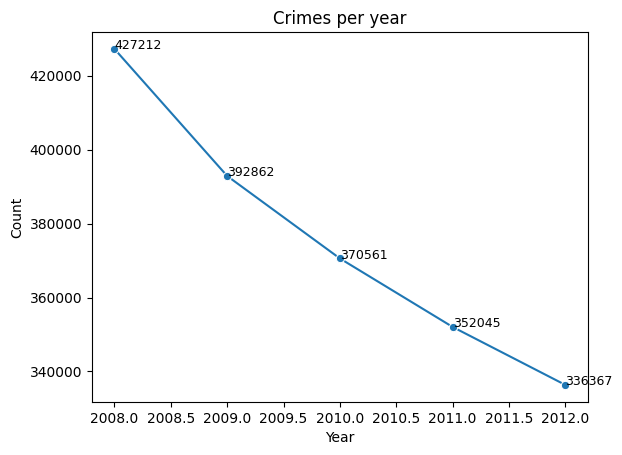

In [16]:
# Create a line plot to visualize trend in total crime counts

sns.lineplot(data = crimes_per_year, x= 'Year', y= 'Count', marker='o')
for i, row in crimes_per_year.iterrows():
    plt.text(row['Year'], row['Count'], str(row['Count']), fontsize=9)
plt.title('Crimes per year')
plt.show()

In [55]:
crimes_in_2008 = crimes_per_year.loc[crimes_per_year['Year'] == 2008, 'Count'].values[0]
crimes_in_2012 = crimes_per_year.loc[crimes_per_year['Year'] == 2012, 'Count'].values[0]

between_2008_2012 = crimes_in_2012 - crimes_in_2008


print(f'Crimes has decreased with {abs(between_2008_2012):,} crimes from 2008 - 2012')


Crimes has decreased with 90,845 crimes from 2008 - 2012


**3.4** By how many percentage points has the crime rate increased/decreased over this period? 

Hint: You only need to compare the number of crime records from 2008 with the number of crime records from 2012.

In [56]:
# Calculate the percentage change in total crimes from 2008 to 2012

percentage_crimes = ((crimes_in_2012 - crimes_in_2008) / crimes_in_2008) * 100

print(f'Crimes decreased with {abs(percentage_crimes):.2f}% from 2008 - 2012.')


Crimes decreased with 21.26% from 2008 - 2012.


**3.5** Which primary crime types have increasing crime rates, and which ones have decreasing crime rates, when comparing 2008 to 2012?

In [19]:
crimes_type_and_year =(chicago_crime_2008_to_2012_df.groupby(['Primary Type', 'Year']).size().unstack(fill_value=0))
crimes_type_and_year = pd.DataFrame(crimes_type_and_year)
crimes_type_and_year.head(5)

Year,2008,2009,2010,2011,2012
Primary Type,,,,,
ARSON,644,616,522,504,469
ASSAULT,25448,22861,21537,20411,19900
BATTERY,75930,68460,65403,60460,59132
BURGLARY,26218,26767,26422,26620,22844
CRIM SEXUAL ASSAULT,1500,1390,1319,1441,1379


In [20]:
crime_type_change = crimes_type_and_year[2012]-crimes_type_and_year[2008]
crime_type_change.head()

Primary Type
ARSON                   -175
ASSAULT                -5548
BATTERY               -16798
BURGLARY               -3374
CRIM SEXUAL ASSAULT     -121
dtype: int64

In [58]:
increasing_crimes = crime_type_change[crime_type_change > 0].sort_values()
decreasing_crimes = crime_type_change[crime_type_change < 0].sort_values()

print('Top 10 crime types that increased (2008-2012):')
print()
print(increasing_crimes.head(10))
print('---------------------------------------------')
print('Top 10 crime types that decreased (2008-2012):')
print()
print(decreasing_crimes.head(10))


Top 10 crime types that increased (2008-2012):

Primary Type
HOMICIDE                              2
OBSCENITY                            13
PUBLIC INDECENCY                     13
STALKING                             17
CRIMINAL SEXUAL ASSAULT              24
WEAPONS VIOLATION                    30
INTERFERENCE WITH PUBLIC OFFICER    648
dtype: int64
---------------------------------------------
Top 10 crime types that decreased (2008-2012):

Primary Type
CRIMINAL DAMAGE     -16988
BATTERY             -16798
THEFT               -12973
NARCOTICS           -11017
OTHER OFFENSE        -9008
ASSAULT              -5548
CRIMINAL TRESPASS    -4094
BURGLARY             -3374
ROBBERY              -3219
PROSTITUTION         -2937
dtype: int64


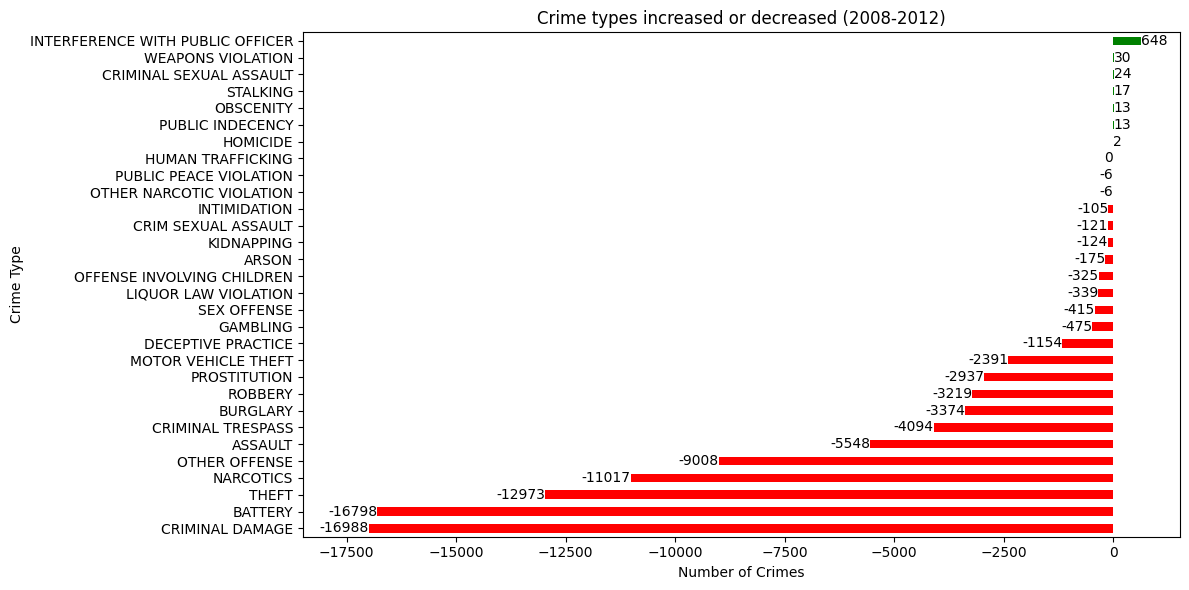

In [22]:
sorted_change = crime_type_change.sort_values()

colors = ['green' if x > 0 else 'red' for x in sorted_change]

plt.figure(figsize=(12,6))
sorted_change.plot(kind='barh', color=colors)

for i, value in enumerate(sorted_change):
    plt.text(value, i, str(value), va='center',
                         ha='left' if value > 0 else 'right',
                         color='black', fontsize=10)

plt.title("Crime types increased or decreased (2008-2012)")
plt.xlabel("Number of Crimes")
plt.ylabel("Crime Type")
plt.xlim(-18500)
plt.tight_layout()
plt.show()



3.1 - I did an exploratory review of the dataset by:

showing the first few rows

checking data types

cheking unique categories and frequencies

3.2 - I counted the number of crimes per year

3.3 - used loc and values to see how much crimes had decreased from 2008-2012

3.4 - I calculated the percentage change between 2008 and 2012.

3.5 - I compared the crime types 2008 vs. 2012. I visualized the results in a horizontal bar plot with colors for increase/decrease.

# 4 - Chicago Police Departement performance assesment

**4.1** How many recorded crimes have in total led to an arrest? What's the corresponding arrest percentage?

In [23]:
# Total number of crimes
total_crimes = len(chicago_crime_2008_to_2012_df)

# Total number oc arrests
total_arrests = chicago_crime_2008_to_2012_df['Arrest'].sum()

# Calculate of arrest percentage 
arrest_percentage = (total_arrests/total_crimes) * 100

print(f'total crimes: {total_crimes}')
print(f'Total arrests: {total_arrests}')
print(f'Aresst precentage: {arrest_percentage:.2f}%')

total crimes: 1879047
Total arrests: 508427
Aresst precentage: 27.06%


**4.2** Has the arrest rate percentage been increasing, decreasing or remained stable over these years?

In [24]:
# Group by year and calvulate arrest and total crimes
arrest_stats = chicago_crime_2008_to_2012_df.groupby('Year').agg(total_crimes=('Arrest', 'count'),arrests=('Arrest', 'sum'))

# Calculate arrest rate
arrest_stats['arrest_rate'] = (arrest_stats['arrests']/ arrest_stats['total_crimes']) * 100
arrest_stats['arrest_rate'] = arrest_stats['arrest_rate'].round(2)

arrest_stats

,total_crimes,arrests,arrest_rate
Year,,,
2008,427212,110028,25.75
2009,392862,110848,28.22
2010,370561,100562,27.14
2011,352045,96304,27.36
2012,336367,90685,26.96


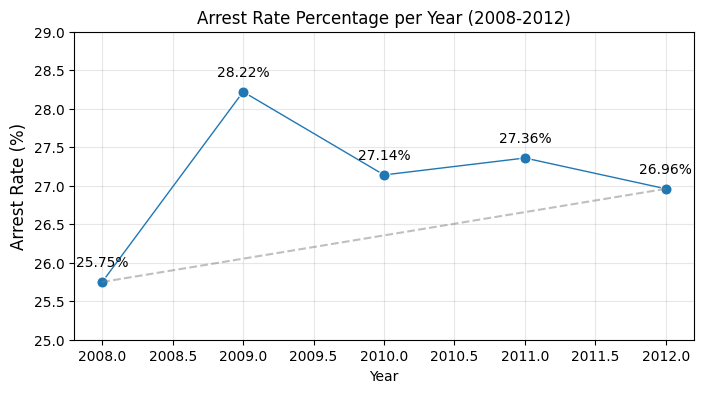

Arrest decreased with 1.21% from 2008 to 2012


In [25]:
stats_2008 = arrest_stats.loc[2008, 'arrest_rate']
stats_2012 = arrest_stats.loc[2012, 'arrest_rate']

diff_2008_2012 = stats_2012-stats_2008


plt.figure(figsize=(8,4))
sns.lineplot(data=arrest_stats, x=arrest_stats.index, y='arrest_rate', marker='o', linewidth=1, markersize=8)
plt.title("Arrest Rate Percentage per Year (2008-2012)", fontsize=12)
plt.xlabel("Year", fontsize=10)
plt.ylabel("Arrest Rate (%)", fontsize=12, )
plt.ylim(25,29)
for year, value in arrest_stats['arrest_rate'].items():
    plt.text(year, value + 0.2, f"{value:.2f}%", ha='center', fontsize=10)
plt.grid(alpha=0.3)
plt.plot([2008, 2012], [arrest_stats.loc[2008, 'arrest_rate'], arrest_stats.loc[2012, 'arrest_rate']], linestyle="--", color="gray", alpha=0.5)
plt.show()



print(f'Arrest decreased with {diff_2008_2012:.2f}% from 2008 to 2012')

**4.3** For the Year 2011, which month has the highest arrest percentage?

In [26]:
# Count percentege per month in 2011

crime_2011 = chicago_crime_2008_to_2012_df[chicago_crime_2008_to_2012_df['Year'] == 2011]
arrested_by_month = crime_2011.groupby('Month')['Arrest'].agg(['sum', 'count'])
arrested_by_month['arrest_rate_percentage'] = (arrested_by_month['sum'] / arrested_by_month['count']) * 100
arrested_by_month['arrest_rate_percentage']= arrested_by_month['arrest_rate_percentage'].round(2)

max_arrest_month = arrested_by_month['arrest_rate_percentage'].idxmax()
max_value = arrested_by_month['arrest_rate_percentage'].max()

print(f'The highest arrest percentage in 2011 was month {max_arrest_month} with {max_value}%.')


The highest arrest percentage in 2011 was month 3 with 29.3%.


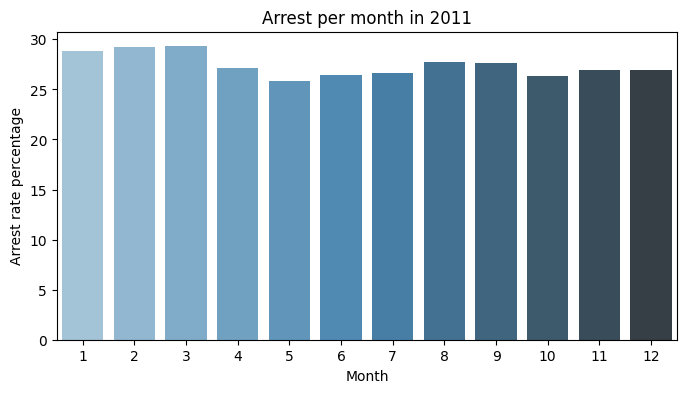

In [27]:
# Plot over year 2011, wich month with the higest arrest

plt.figure(figsize=(8,4))
sns.barplot(data=arrested_by_month, x=arrested_by_month.index, y='arrest_rate_percentage', palette='Blues_d')
plt.title('Arrest per month in 2011')
plt.ylabel('Arrest rate percentage')
plt.show()

**4.4** For the same year, and the particular month of you've identified in question 2.3, which primary crime type has the highest number of arrests?

In [59]:
# masking the data with year and month 

max_crime_month_2011 = chicago_crime_2008_to_2012_df[(chicago_crime_2008_to_2012_df['Year'] == 2011) & (chicago_crime_2008_to_2012_df['Month'] == max_arrest_month)] 
arrest_by_type = max_crime_month_2011.groupby('Primary Type')['Arrest'].sum()

max_arrest_type = arrest_by_type.idxmax()
max_arrest_count = arrest_by_type.max()

print(f'The Primary Crime Type with the highest number of arrests in {max_arrest_month}/2011 is: {max_arrest_type} ({max_arrest_count} arrests)')

The Primary Crime Type with the highest number of arrests in 3/2011 is: NARCOTICS (3747 arrests)


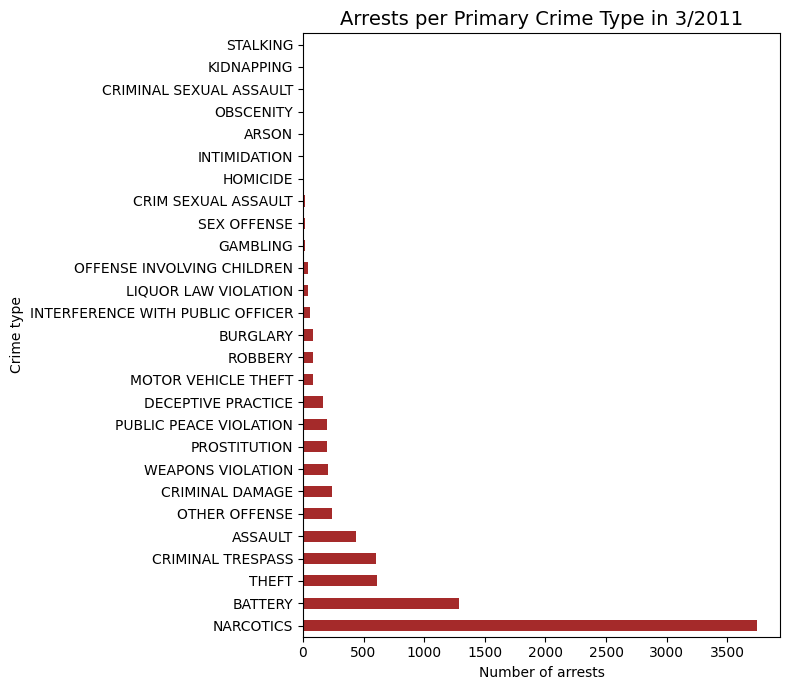

In [60]:
plt.figure(figsize=(8,7))
arrest_by_type.sort_values(ascending=False).plot(kind='barh', color='brown')
plt.title(f'Arrests per Primary Crime Type in {max_arrest_month}/2011', fontsize=14)
plt.ylabel('Crime type')
plt.xlabel('Number of arrests')
plt.tight_layout()
plt.show()


4 - Chicago Police Department Performance Assessment

In this i analyzed how the Chicago Police Department performed in terms of arrests between 2008 and 2012. I examined total arrests, arrest rates by year, and the months and crime types with the highest arrest rates.

4.1 Total Arrests
- Total number of crimes during the period 2008-2012: 1,879,047
- Total number of arrests: 508,427
- Total arrest rate: 27.06% 
This shows that approximately one in four crimes resulted in an arrest during this period.

4.2 Arrest Rate Trend (2008-2012)
- The arrest rate has decreased by 1.21% from 2008 25.75% to 2012 26.96%. 
- The diagram shows that the arrest rate between years, with a peak of 28.22% in 2009.

4.3 Highest arrest month of 2011
- Month 3 (Mars) had the highest arrest rate: 29.3%. 
- Police arrests were most effective during this month, relative to the number of crimes committed.

4.4 Crime type with the most arrests in the highest arrest month (March 2011)
- The crime type NARCOTICS led to the most arrests: 3,747. 
- The bar plot shows the arrests by crime type during the month, with drug offenses as the most prevalent.
 
The analysis shows that the arrest rate is relatively stable with a decline during the period. March 2011 was the most of arrest rate, drug offenses were the crime type that most often resulted in arrests during that month. This can provide insight into police priorities and effectiveness over time.

# 5 - Troubles at home

**5.1** How many recorded crimes are domestic?

In [30]:
# Count total domestic crimes

total_domestic_crime = chicago_crime_2008_to_2012_df['Domestic'].sum()

print(f' Total domestic crimes: {total_domestic_crime}.')

 Total domestic crimes: 309845.


**5.2** How many domestic recorded crimes are of the primary type *offense involving children*?

In [31]:
# Filter domestic offenses involving children

domestic_children_df = chicago_crime_2008_to_2012_df[
    (chicago_crime_2008_to_2012_df['Domestic'] == True) &
    (chicago_crime_2008_to_2012_df['Primary Type'] == 'OFFENSE INVOLVING CHILDREN')
]

domestic_children_count = len(domestic_children_df)

print(f' Domestic crimes involving children: {domestic_children_count}')

 Domestic crimes involving children: 10983


**5.3** How much more likely is it that an offense involving children is domestic?

In [63]:
# Total number of offense involving children 

children_total = len( chicago_crime_2008_to_2012_df[chicago_crime_2008_to_2012_df['Primary Type'] == 'OFFENSE INVOLVING CHILDREN'])

# Total domestic probability
total_domestic_prob = chicago_crime_2008_to_2012_df['Domestic'].mean()

# Probability that a child offense is domestic
children_domestic_prob = domestic_children_count / children_total

# How much more likely a child offense is to be domestic
probability_crime_domestic = children_domestic_prob / total_domestic_prob


print(f'Total child offenses: {children_total}')
print(f'Domestic child offenses: {domestic_children_count}')
print(f'Probability any crime is domestic: {total_domestic_prob:.2%}')
print(f'Probability child offense is domestic: {children_domestic_prob:.2%}')
print(f'Offenses involving children are {probability_crime_domestic:.2f} times more likely to be domestic.')


Total child offenses: 12750
Domestic child offenses: 10983
Probability any crime is domestic: 16.49%
Probability child offense is domestic: 86.14%
Offenses involving children are 5.22 times more likely to be domestic.


**5.4** What's the worst weekday in terms of number of domestic offenses involving children? How does it compare to the other weekdays?

Number of domestic offenses involving children per weekday:
Weekday
Friday       2033
Saturday     1725
Sunday       1691
Thursday     1440
Tuesday      1401
Wednesday    1378
Monday       1315
Name: count, dtype: int64
The worst weekday is Friday with 2033 offenses.


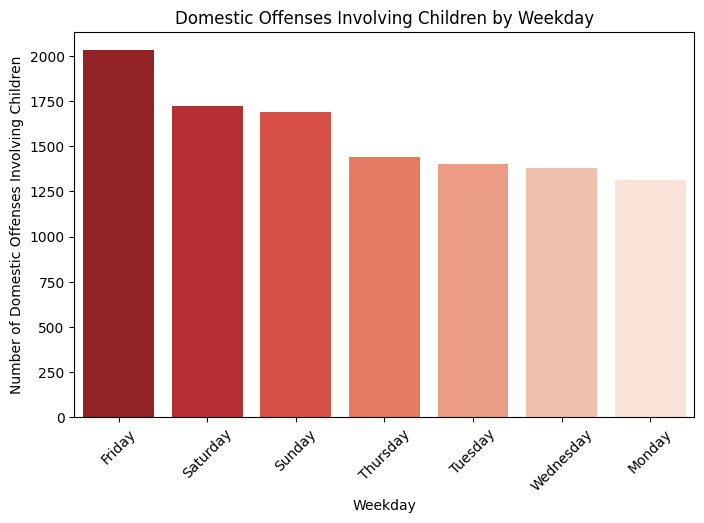

In [62]:
# Count domestic offenses involving children by weekday

weekday_counts = domestic_children_df['Weekday'].value_counts()
print('Number of domestic offenses involving children per weekday:')
print(weekday_counts)

worst_weekday = weekday_counts.idxmax()
worst_count = weekday_counts.max()
print(f'The worst weekday is {worst_weekday} with {worst_count} offenses.')

# Visualize the weekday distribution

plt.figure(figsize=(8,5))
sns.barplot(x=weekday_counts.index, y=weekday_counts.values, palette='Reds_r')
plt.xlabel('Weekday')
plt.ylabel('Number of Domestic Offenses Involving Children')
plt.title('Domestic Offenses Involving Children by Weekday')
plt.xticks(rotation=45)
plt.show()

**5.5** What's the distribution, in terms of number of records, for domestic crimes of sexual character that involves children? What's the arrest rate (%) for each? 

In [65]:
# Filter domestic sexual crimes involving children

domestic_sexual_children_df = chicago_crime_2008_to_2012_df[
    (chicago_crime_2008_to_2012_df['Domestic'] == True) &  # Only domestic crimes
    (chicago_crime_2008_to_2012_df['Primary Type'].str.contains('SEX', case=False)) &  # Sexual crimes
    (chicago_crime_2008_to_2012_df['Description'].str.contains('CHILD', case=False, na=False))  # Involves children
]

# Count number of records per crime type

distribution = domestic_sexual_children_df['Primary Type'].value_counts()
print('Distribution of domestic sexual crimes involving children:')
print(distribution)
print()

# Arrest rate percent per crime type

arrest_rate = domestic_sexual_children_df.groupby('Primary Type')['Arrest'].mean() * 100
arrest_rate = round(arrest_rate, 2)
print('Arrest rate percentage for each type:')
print(arrest_rate)

Distribution of domestic sexual crimes involving children:
Primary Type
SEX OFFENSE    84
Name: count, dtype: int64

Arrest rate percentage for each type:
Primary Type
SEX OFFENSE    16.67
Name: Arrest, dtype: float64


**5.6** What period of the day does the specific kind of (domestic) offense against children, with the most recorded arrests, tend do occur? How does it look for all weekdays individually?
        Can you find certain periods of the week that are especially bad? 

    Note: the details of this question is up to you to interpret

In [66]:
# Filter domestic offenses involving children that resulted in an arrest
domestic_children_arrests = domestic_children_df[domestic_children_df['Arrest'] == True]

# Count arrests by Primary Type
arrest_counts_by_type = domestic_children_arrests['Primary Type'].value_counts()
most_arrested_type = arrest_counts_by_type.idxmax()
print(f'Most arrested offense type: {most_arrested_type} ({arrest_counts_by_type.max()} arrests)')

Most arrested offense type: OFFENSE INVOLVING CHILDREN (2204 arrests)


In [36]:
most_arrested_offense_df = domestic_children_arrests[
    domestic_children_arrests['Primary Type'] == most_arrested_type
]

In [67]:
# Count occurrences per hour
hourly_counts = most_arrested_offense_df['Hour'].value_counts().sort_index()
print('Number of offenses per hour:')
print(hourly_counts)

Number of offenses per hour:
Hour
0     378
1      49
2      29
3      21
4      13
5      21
6      25
7      56
8      90
9      85
10     82
11     63
12    114
13     86
14     92
15    114
16    130
17    119
18    124
19    117
20    123
21    103
22    106
23     64
Name: count, dtype: int64


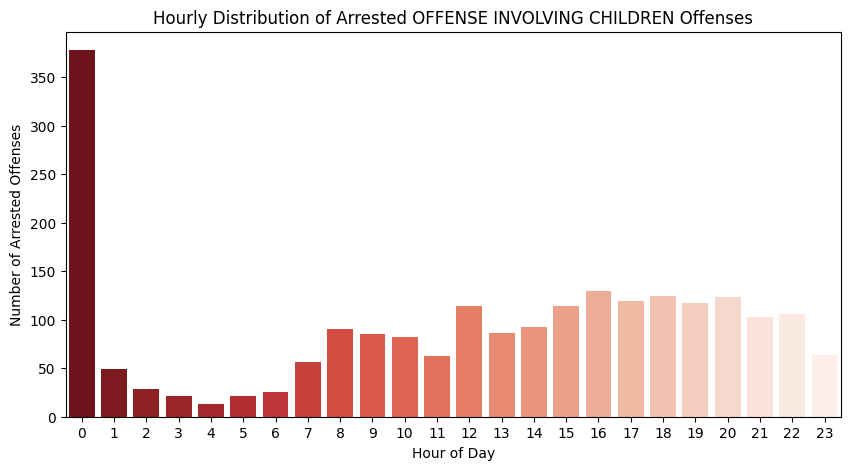

In [68]:
plt.figure(figsize=(10,5))
sns.barplot(x=hourly_counts.index, y=hourly_counts.values, palette='Reds_r')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Arrested Offenses')
plt.title(f'Hourly Distribution of Arrested {most_arrested_type} Offenses')
plt.show()

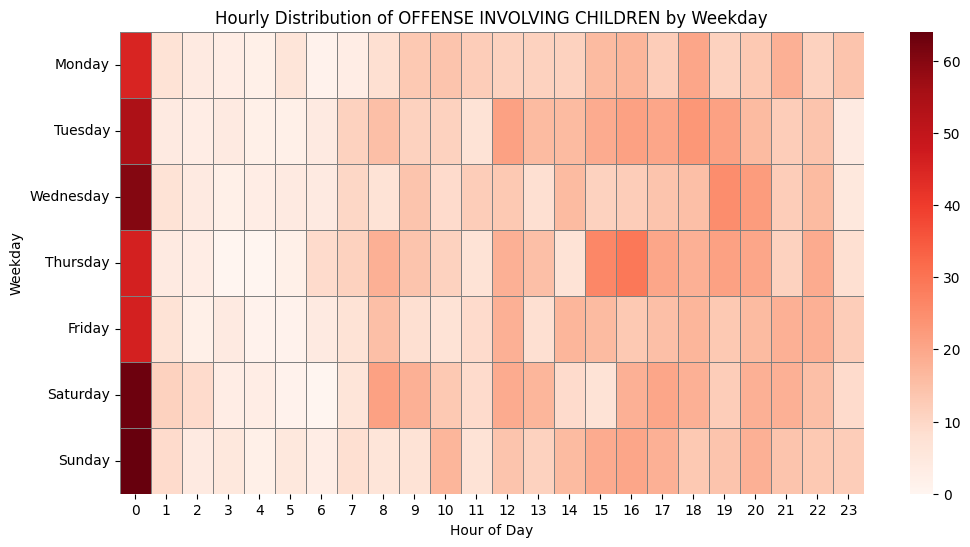

In [70]:
# Count by weekday and hour
weekday_hour_counts = most_arrested_offense_df.groupby(['Weekday', 'Hour']).size().reset_index(name='Count')

# Heatmap for visualization
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_hour_counts['Weekday'] = pd.Categorical(weekday_hour_counts['Weekday'], categories=weekday_order, ordered=True)

heatmap_data = weekday_hour_counts.pivot(index='Weekday', columns='Hour', values='Count').fillna(0)

plt.figure(figsize=(12,6))
sns.heatmap(heatmap_data, cmap='Reds', linewidths=0.5, linecolor='gray')
plt.title(f'Hourly Distribution of {most_arrested_type} by Weekday')
plt.ylabel('Weekday')
plt.xlabel('Hour of Day')
plt.show()


Insights from the hourly distribution:

-Most domestic offenses involving children occur between 18:00 and 22:00.

-The early morning hours (0:00–6:00) have the fewest offenses.

Insights from the weekday-hour heatmap:

-Fridays and Saturdays generally show higher numbers of offenses compared to other weekdays.

-Peak hours (18:00–22:00) are consistently the worst across most weekdays.

-Sundays show moderate activity, with slightly fewer offenses than Friday/Saturday evenings.

In [74]:
active_hour = most_arrested_offense_df['Hour'].mode()[0]
active_weekday = most_arrested_offense_df['Weekday'].mode()[0]
print(f'Peak period: {active_weekday} around {active_hour}:00 hours.')


Peak period: Saturday around 0:00 hours.


    **5.7** Looking at any given year as a whole, what's the worst period in terms of domestic number of offenses involving children? Can you find any trends? Does the trend seem to be consistent for every other year? 

        Note: the details of this question is up to you to interpret

In [75]:
# Group by Year and Month, count offenses
monthly_counts = domestic_children_df.groupby(['Year', 'Month']).size().reset_index(name='crime_count')
monthly_counts.head()

,Year,Month,crime_count
0,2008,1,233
1,2008,2,163
2,2008,3,184
3,2008,4,170
4,2008,5,191


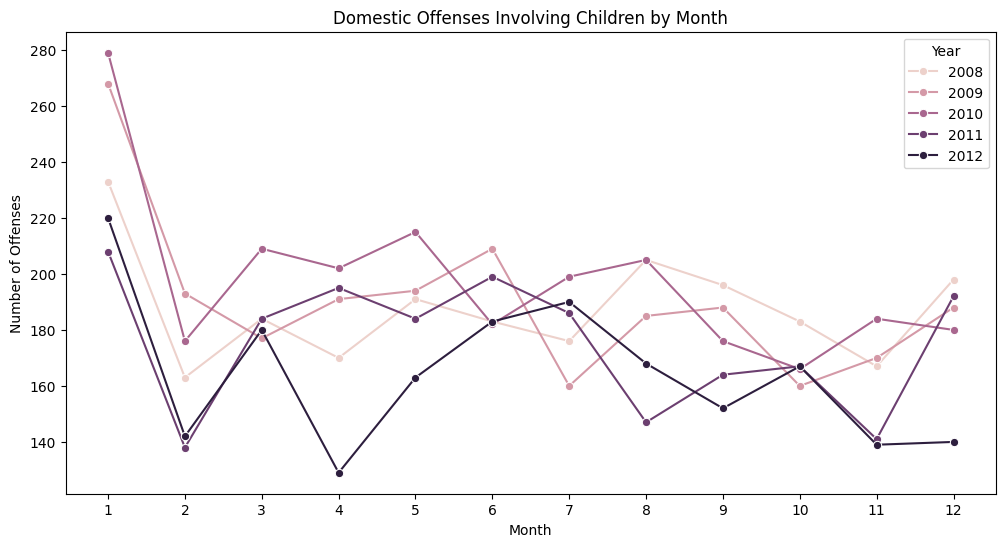

In [79]:
plt.figure(figsize=(12,6))
sns.lineplot(data=monthly_counts, x='Month', y='crime_count', hue='Year', marker='o')
plt.title('Domestic Offenses Involving Children by Month')
plt.xlabel('Month')
plt.ylabel('Number of Offenses')
plt.xticks(range(1,13))
plt.legend(title='Year')
plt.show()

In [80]:
worst_month_per_year = monthly_counts.loc[monthly_counts.groupby('Year')['crime_count'].idxmax()]
print('Worst month per year for domestic offenses involving children:')
print(worst_month_per_year)

Worst month per year for domestic offenses involving children:
    Year  Month  crime_count
0   2008      1          233
12  2009      1          268
24  2010      1          279
36  2011      1          208
48  2012      1          220


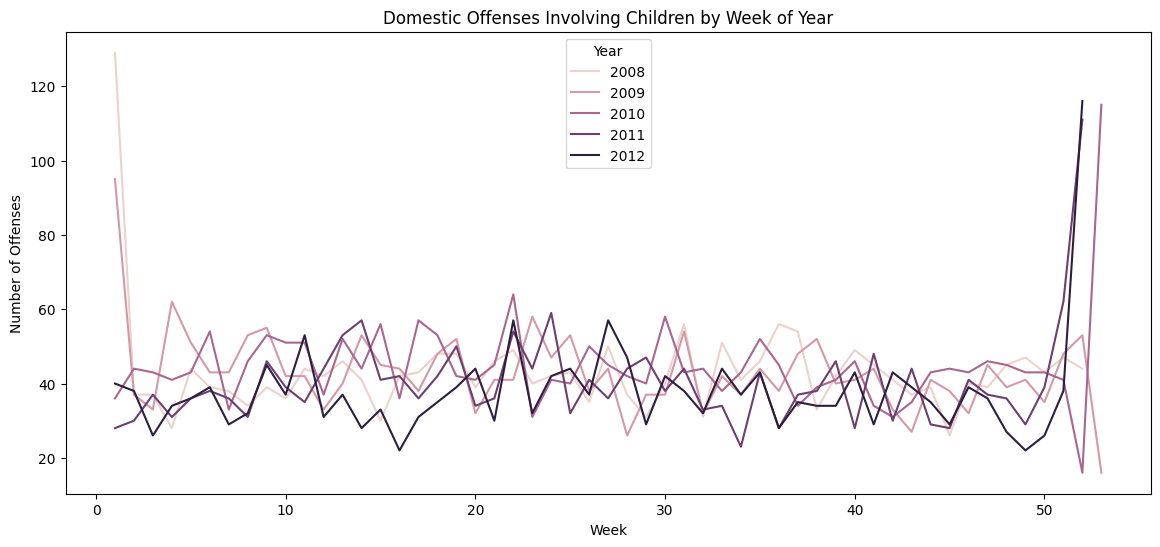

In [83]:
# Create Week column
domestic_children_df['Week'] = domestic_children_df['Date'].dt.isocalendar().week

# Count offenses per week and year
weekly_counts = domestic_children_df.groupby(['Year', 'Week']).size().reset_index(name='crime_count')

plt.figure(figsize=(14,6))
sns.lineplot(data=weekly_counts, x='Week', y='crime_count', hue='Year')
plt.title('Domestic Offenses Involving Children by Week of Year')
plt.xlabel('Week')
plt.ylabel('Number of Offenses')
plt.show()

5.1 Total domestic crimes
- Total number of domestic crimes: 309,845.
- Domestic crimes of all recorded crimes.

5.2 Domestic crimes involving children
- Number of domestic crimes with children as victims: 10,983
- With a domestic_children mask.

5.3 Probability that a child-related crime is domestic
- Total number of child-related crimes: 12,750
- Proportion of domestic crimes overall: 16.49%
- Proportion of child-related crimes as domestic: 86.14%
- Child-related crimes are 5.22 times more likely to be domestic compared to all crimes.

5.4 Worst day of the week for domestic crimes involving children
- Worst day: Friday, with 2,033 crimes
- Other days have fewer crimes: Saturday 1,725, Sunday 1,691, Monday 1,315

5.5 Domestic sexual crimes involving children
- Primary type: SEX OFFENSE
- Number of crimes: 84
- Arrest rate: 16.67%
- Shows that these crimes are uncommon but serious, with a relatively low arrest rate.

5.6 Time analysis of child-related domestic crimes
- Most arrests occur between 18:00–22:00
- Heatmap shows high activity on Friday and Saturday evenings
- Peak period: Saturday around 0:00

5.7 Monthly and weekly trends
- Worst month per year (2008–2012) is usually January
- Weekly trend shows peaks at the beginning of the year but changes through the year
- The trend is relatively consistent over the years
 
The analysis shows that child related domestic crimes are both common and concentrated on certain days of the week and evenings. 

Arrest rates are higher for child-related crimes than for all crimes, but still low for certain types such as sexual offenses. 

These insights can be used for targeted policing and preventive measures.

# 6 - Bad Boys Bad Boys whatcha gonna do

**6.1** In general, what weekday is a crime most likely to occur? Which day is the safest?

**6.2** Which is the most unsafe weekday for you if you'd like to avoid the following:

a) getting your phone stolen by sneaky pickpockets (THEFT) 

b) having your handbag forcibly pulled away (ROBBERY) 

c) getting jumped in an alley (ASSAULT)

**6.3** Which are the worst 10 dates (most recorded crimes) of 2008? Does this trend hold for the other years?

**6.4** From the perspective of total number of crime records, which are the Top 10 primary crime types? Which are the Bottom 10? 

Consider this question for the years 2008-2012 as a whole. 

**6.5** For all those crime categories you identified in 6.4, how does their distribution instead look per year - rather than the full 2008-2012 period as a whole?

**6.6** Which primary crime types does the city of Chicago seem to get better at preventing? For which ones is it the opposite, i.e, the situation is getting worse? 

# 7 - Night Stalker

**7.1** Are there more or less crimes reported during daytime, compared with nighttime? Daytime is considered as all hours between 06:00-18:00, nighttime is the rest of the day.

**7.2** Are there any specific primary crime types that most often occur during nights? Which ones are they?

**7.3** In general, for each weekday, how many crimes are recorded during daytime and how many during nighttime? What are the trends? Are there any weekdays that stands out somehow?

Monday, Tuesday, Wednesday, Thursday and Friday have overwhelmingly more recorded crimes during the day, than during the night.

Saturday also has more records during the day, but it's only slightly more than durnig the night.

Sunday is a trend breaker - wherein the number of recorded crimes are higher during the night, than during the night. Though not by alot.

**7.4** Does the trends you've found in 7.3 also hold if you look at each year individually?

**7.5** Are there any weekdays in which Stalking occurs more often during nighttime?

# 8 - Grand Theft Auto

**8.1** You just bought a new car. What weekday should you be most wary of as it has the highest risk for a Grand Theft Auto-style robbery (MOTOR VEHICLE THEFT)?

Worst weekday for Motor Vehicle Theft: Friday (13622 offenses)


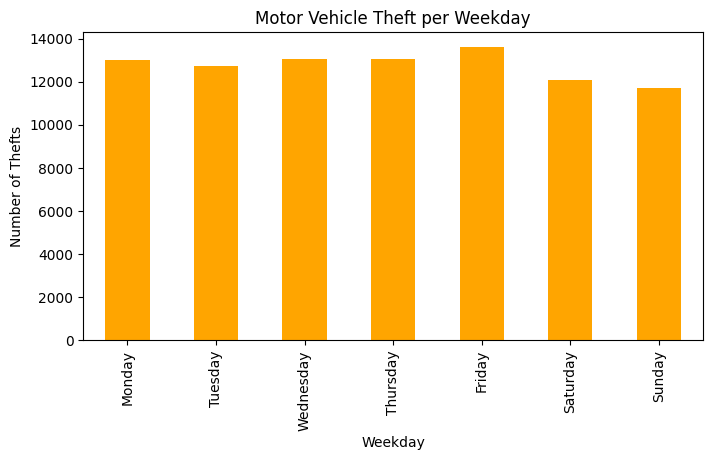

In [84]:
# Filter the data for vehicle theft
gta = chicago_crime_2008_to_2012_df[chicago_crime_2008_to_2012_df['Primary Type'] == 'MOTOR VEHICLE THEFT']

# Count vehicle theft per weekday
weekday_counts = gta['Weekday'].value_counts()

# Count max vehicle thft day
worst_day = weekday_counts.idxmax()
print(f'Worst weekday for Motor Vehicle Theft: {worst_day} ({weekday_counts.max()} offenses)')

# Visualize car thefts by day of the week
plt.figure(figsize=(8,4))
weekday_counts = weekday_counts.reindex(['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'])
weekday_counts.plot(kind='bar', color='orange')
plt.title('Motor Vehicle Theft per Weekday')
plt.ylabel('Number of Thefts')
plt.show()

**8.2** For that day, where (at what location) should you absolutely avoid leave your car carelessly? Where is it seemingly safest to do so?

In [86]:
# count vehicle theft per location
location_counts = gta['Location Description'].value_counts()

print('Top 5 most risky locations:')
print(location_counts.head(5))
print()
print('Top 5 safest locations (least frequent, non-zero):')
print(location_counts[location_counts>0].tail(5))

Top 5 most risky locations:
Location Description
STREET                            72595
PARKING LOT/GARAGE(NON.RESID.)     5864
OTHER                              1799
RESIDENTIAL YARD (FRONT/BACK)      1637
ALLEY                              1227
Name: count, dtype: int64

Top 5 safest locations (least frequent, non-zero):
Location Description
ANIMAL HOSPITAL                      1
CURRENCY EXCHANGE                    1
CTA BUS                              1
FEDERAL BUILDING                     1
COLLEGE/UNIVERSITY RESIDENCE HALL    1
Name: count, dtype: int64


**8.3*** Are there certain periods of the year/month/day/time of day where GTA is more frequent?

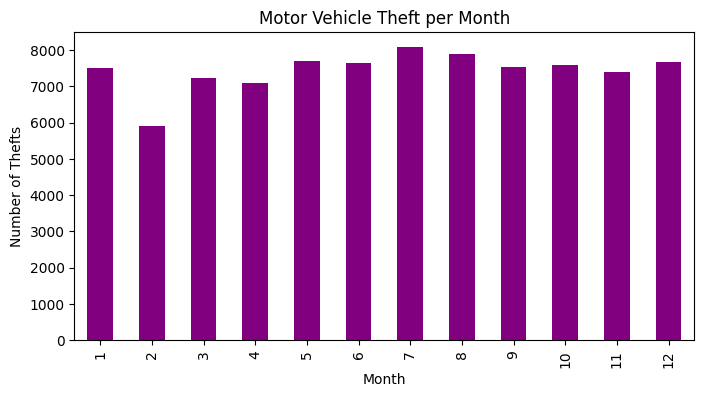

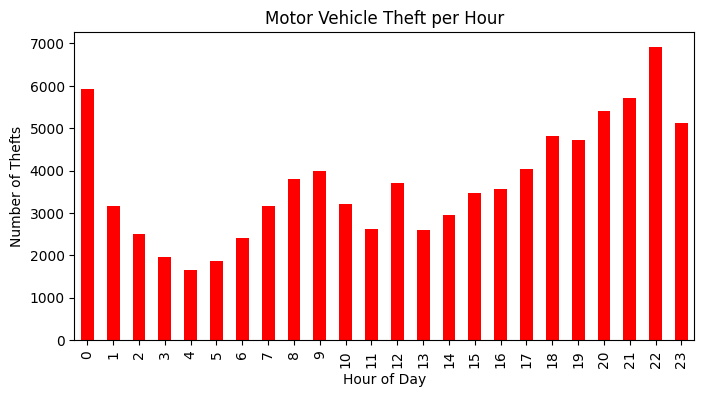

In [87]:
# Vehicle thefth per month
monthly_counts = gta.groupby('Month').size()
plt.figure(figsize=(8,4))
monthly_counts.plot(kind='bar', color='purple')
plt.title('Motor Vehicle Theft per Month')
plt.xlabel('Month')
plt.ylabel('Number of Thefts')
plt.show()

# Vehicle theft per hour
hourly_counts = gta.groupby('Hour').size()
plt.figure(figsize=(8,4))
hourly_counts.plot(kind='bar', color='red')
plt.title('Motor Vehicle Theft per Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Thefts')
plt.show()

Conclusion: 
- Be extra careful with your car on Fridays, especially on streets, parking lots and in residential areas. 
- Try to park in safe places such as schools, bank areas or well-monitored areas. 
- Security measures should be prioritized during the afternoon/evening and during the summer months.

# 9. Just send me like location

https://www.youtube.com/watch?v=k7yBJ5Ffkdo

**9.1** Are there any (geographical) areas hit particularly hard by prostitution on friday nights?

In [48]:
chicago_crime_2008_to_2012_df['Primary Type']

0                        BURGLARY
1                           THEFT
2          PUBLIC PEACE VIOLATION
3                        BURGLARY
4                           THEFT
                    ...          
1879042               SEX OFFENSE
1879043        DECEPTIVE PRACTICE
1879044        DECEPTIVE PRACTICE
1879045                     THEFT
1879046        DECEPTIVE PRACTICE
Name: Primary Type, Length: 1879047, dtype: object

**9.2** Can you vizualise the locations from 9.1 on a map of Chicago? Is there a concentration somewhere? 

**9.3*** Can you find any geographical concentration of other crime categories? Perhaps even by weekday and or day/nighttime? Plot these on a map of Chicago. 

# 10 - The $ factor

**10.1** Merge the crime and census datasets together in a suitable way.

In [49]:
# renam the column in the census dataframe, Community Area exists for merging

chicago_census_2008_to_2012_df = chicago_census_2008_to_2012_df.rename(columns={'Community Area Number': 'Community Area'})

# Merge dataset 
merge_crime_census_df = chicago_crime_2008_to_2012_df.merge(chicago_census_2008_to_2012_df, on= 'Community Area', how= 'left')

merge_crime_census_df.head()

,ID,Case Number,Date,Block,IUCR,Primary Type,Description,Location Description,Arrest,Domestic,...,Hour,Minute,COMMUNITY AREA NAME,PERCENT OF HOUSING CROWDED,PERCENT HOUSEHOLDS BELOW POVERTY,PERCENT AGED 16+ UNEMPLOYED,PERCENT AGED 25+ WITHOUT HIGH SCHOOL DIPLOMA,PERCENT AGED UNDER 18 OR OVER 64,PER CAPITA INCOME,HARDSHIP INDEX
0,8953937,HW102973,2012-12-31 23:58:00,037XX N NORA AVE,0610,BURGLARY,FORCIBLE ENTRY,RESIDENCE-GARAGE,False,False,...,23,58,Dunning,5.2,10.6,10.0,16.2,33.6,26282.0,28.0
1,8954299,HW100700,2012-12-31 23:55:00,058XX S MARYLAND AVE,0890,THEFT,FROM BUILDING,HOSPITAL BUILDING/GROUNDS,False,False,...,23,55,Hyde Park,1.5,18.4,8.4,4.3,26.2,39056.0,14.0
2,8950836,HW100039,2012-12-31 23:55:00,0000X E OHIO ST,2890,PUBLIC PEACE VIOLATION,OTHER VIOLATION,SIDEWALK,True,False,...,23,55,Near North Side,1.9,12.9,7.0,2.5,22.6,88669.0,1.0
3,8950918,HW100021,2012-12-31 23:55:00,035XX W MONTROSE AVE,0610,BURGLARY,FORCIBLE ENTRY,OTHER,False,False,...,23,55,Irving Park,6.3,13.1,10.0,22.4,31.6,27249.0,34.0
4,8951459,HW100757,2012-12-31 23:50:00,028XX N HALSTED ST,0890,THEFT,FROM BUILDING,RESIDENCE,False,False,...,23,50,Lake View,1.1,11.4,4.7,2.6,17.0,60058.0,5.0


**10.2*** Are there certain kinds of socoeconomic area that are more prone to certain kinds of crimes? Do a deep dive in the direction you fancy yourself here.

In [50]:
# Count number of crimes per comunity area

crime_count = merge_crime_census_df.groupby('Community Area').size().reset_index(name='crime_count')
crime_count.head(5)

,Community Area,crime_count
0,0.0,25
1,1.0,28099
2,2.0,24059
3,3.0,26026
4,4.0,12644


In [51]:
# Calculate average economic values per community area

socoeconomic_area = merge_crime_census_df.groupby('Community Area').agg({ 'PERCENT HOUSEHOLDS BELOW POVERTY': 'mean',
                                                                         'PER CAPITA INCOME ': 'mean',
                                                                         'HARDSHIP INDEX': 'mean'
                                                                         }).reset_index()

socoeconomic_area.head()

,Community Area,PERCENT HOUSEHOLDS BELOW POVERTY,PER CAPITA INCOME,HARDSHIP INDEX
0,0.0,NaN,NaN,NaN
1,1.0,23.6,23939.0,39.0
2,2.0,17.2,23040.0,46.0
3,3.0,24.0,35787.0,20.0
4,4.0,10.9,37524.0,17.0


In [52]:
# remove Nan values

socoeconomic_area = socoeconomic_area.dropna()
socoeconomic_area.head()

,Community Area,PERCENT HOUSEHOLDS BELOW POVERTY,PER CAPITA INCOME,HARDSHIP INDEX
1,1.0,23.6,23939.0,39.0
2,2.0,17.2,23040.0,46.0
3,3.0,24.0,35787.0,20.0
4,4.0,10.9,37524.0,17.0
5,5.0,7.5,57123.0,6.0


In [53]:
# Merge crime counts with socioeconomic indicators

area_summary = crime_count.merge(socoeconomic_area, on='Community Area', how='inner')

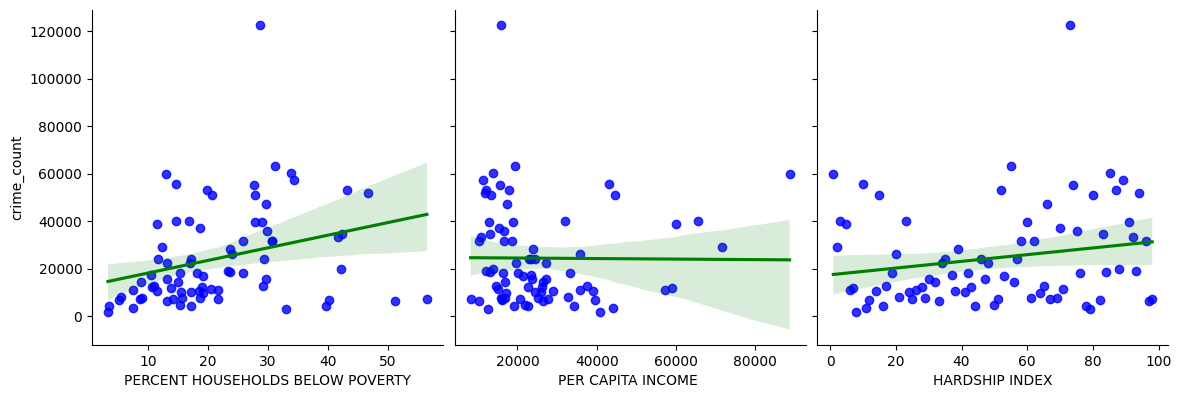

In [54]:
# Visualize relationships between crime count and socioeconomic factors

sns.pairplot(
    area_summary,
    x_vars=['PERCENT HOUSEHOLDS BELOW POVERTY', 'PER CAPITA INCOME ', 'HARDSHIP INDEX'], y_vars='crime_count', height=4, kind='reg',
    plot_kws={'scatter_kws': {'color': 'blue'}, 'line_kws': {'color': 'green'}}
)
plt.show()

10  Socioeconomic Patterns in Crime

In this task, i investigate socioeconomic areas are more prone to crime than others. 

- Merging crime data with census data based on `Community Area`. This gives each area linked to each crime.

- Count the number of crimes per community area to see which areas are most vulnerable.

- Calculate average values ​​for poverty, per capita income, and hardship index by area. 
missing values ​​are removed to get a clean analysis.

Crime statistics and socioeconomic indicators are merged into `area_summary`.

With a pairplot, the relationship between crime rates and socioeconomic factors. Regression lines help us see whether, for example, higher poverty or lower income is linked to more crime

# 11 - Your turn!

There are obviously so much more to gain by analysing these datasets. This is now your opportunity to dwelve deeper into what you yourself like.

    Instructions: think of one or several questions (as we've done above). Then, proceed with your own deep dive analysis and provide your answers.